## EDA


In [6]:
# Taufiqurrahman_202431093

import matplotlib.pyplot as plt
import pandas as pd

# Agar grafik langsung muncul di bawah cell Jupyter Notebook
%matplotlib inline

In [3]:
# Taufiqurrahman_202431093

# Membaca dataset dari file CSV
df = pd.read_csv('healthcare-dataset-stroke-data.csv')

# Menampilkan 5 baris pertama data
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [4]:
# Taufiqurrahman_202431093

# Melihat informasi struktur data (tipe data dan jumlah baris/kolom)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


In [5]:
# Taufiqurrahman_202431093

# Melihat ringkasan statistik deskriptif untuk kolom numerik
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [7]:
# Taufiqurrahman_202431093

# Menghitung jumlah nilai kosong (missing values) pada tiap kolom
print('Jumlah data kosong per kolom:')
print(df.isna().sum())

Jumlah data kosong per kolom:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


In [8]:
# Taufiqurrahman_202431093

# Melihat isi nilai unik dari beberapa kolom kategorik
print("Nilai unik kolom 'gender':", df['gender'].unique())
print("Nilai unik kolom 'work_type':", df['work_type'].unique())
print("Nilai unik kolom 'smoking_status':", df['smoking_status'].unique())

Nilai unik kolom 'gender': <StringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str
Nilai unik kolom 'work_type': <StringArray>
['Private', 'Self-employed', 'Govt_job', 'children', 'Never_worked']
Length: 5, dtype: str
Nilai unik kolom 'smoking_status': <StringArray>
['formerly smoked', 'never smoked', 'smokes', 'Unknown']
Length: 4, dtype: str


In [10]:
# Taufiqurrahman_202431093

# Mengisi data kosong dengan penanganan tipe data yang aman
for col in df.columns:
  # Jika kolom bertipe teks/kategori (object atau string)
  if df[col].dtype == 'object' or pd.api.types.is_string_dtype(df[col]):
    if not df[col].mode().empty:
      df[col] = df[col].fillna(df[col].mode()[0])
  # Jika kolom bertipe angka (integer atau float)
  elif pd.api.types.is_numeric_dtype(df[col]):
    df[col] = df[col].fillna(df[col].mean())

# Cek kembali apakah masih ada data kosong
print('Sisa data kosong setelah diisi:')
print(df.isna().sum())

Sisa data kosong setelah diisi:
id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64


In [11]:
# Taufiqurrahman_202431093

# Menghitung jumlah data duplikat sebelum dihapus
print(f'Jumlah data duplikat sebelum dihapus: {df.duplicated().sum()}')

# Menghapus data duplikat dan memperbarui dataframe
df = df.drop_duplicates()

# Memeriksa hasil akhir dengan info()
print('\n--- Informasi Data Setelah Duplikat Dihapus ---')
df.info()

Jumlah data duplikat sebelum dihapus: 0

--- Informasi Data Setelah Duplikat Dihapus ---
<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                5110 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


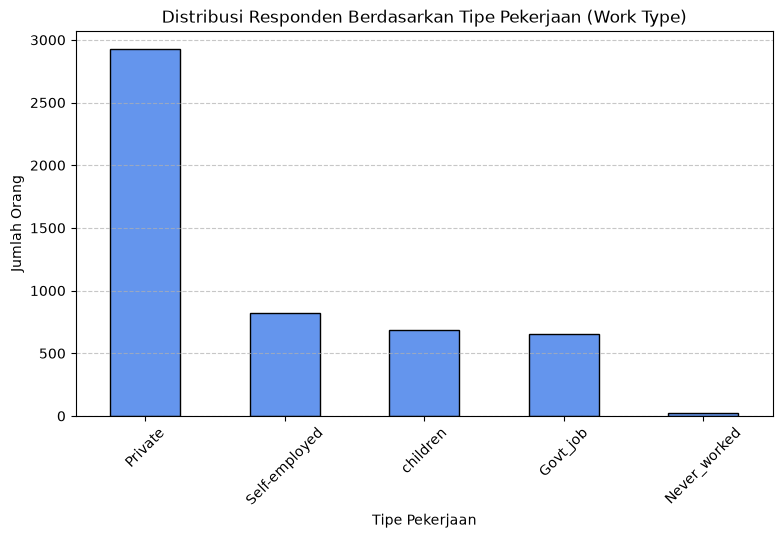

In [12]:
# Taufiqurrahman_202431093

# Membuat grafik batang dari jumlah tiap kategori pada kolom 'work_type'
plt.figure(figsize=(9, 5))
df['work_type'].value_counts().plot(
    kind='bar', color='cornflowerblue', edgecolor='black'
)

# Menambahkan judul dan label sumbu sesuai ketentuan
plt.title(
    'Distribusi Responden Berdasarkan Tipe Pekerjaan (Work Type)', fontsize=12
)
plt.xlabel('Tipe Pekerjaan', fontsize=10)
plt.ylabel('Jumlah Orang', fontsize=10)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Menampilkan visualisasi
plt.show()

## 2. Scraping

In [13]:
# Taufiqurrahman_202431093

import csv
import pandas as pd
import requests
from bs4 import BeautifulSoup

In [14]:
# Taufiqurrahman_202431093

# Tentukan URL halaman Wikipedia
url = 'https://en.wikipedia.org/wiki/List_of_regencies_and_cities_in_Indonesia'

# Header opsional agar dikenali sebagai akses browser yang wajar
headers = {
    'User-Agent': (
        'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML,'
        ' like Gecko) Chrome/120.0.0.0 Safari/537.36'
    )
}

# Ambil halaman web (requests.get)
response = requests.get(url, headers=headers)

# Cek status_code (harus 200)
print(f'Status Code: {response.status_code}')

Status Code: 200


In [15]:
# Taufiqurrahman_202431093

# Ubah isi halaman menjadi objek BeautifulSoup
soup = BeautifulSoup(response.text, 'html.parser')

# Cari semua blok data (tabel wilayah di Wikipedia biasanya menggunakan class 'wikitable')
tables = soup.find_all('class' or 'wikitable')

# Sebagai alternatif yang lebih aman untuk struktur Wikipedia ini, kita ambil tabel pertama/utama
target_table = soup.find('table', {'class': 'wikitable'})
rows = target_table.find_all('tr') if target_table else []

print(f'Jumlah blok baris (tr) ditemukan: {len(rows)}')

regions_data = []

# Iterasi baris tabel (lewati header di index 0)
for row in rows[1:]:
  cols = row.find_all(['td', 'th'])
  if len(cols) >= 5:  # Pastikan kolom mencukupi
    try:
      # Contoh pengambilan atribut dari kolom tabel Wikipedia:
      # Kolom kategori: Nama Wilayah atau Provinsi
      # Kolom angka 1: Luas wilayah atau populasi (jika tersedia di kolom)
      # Kolom angka 2: Kode administratif atau jumlah kecamatan

      # Sesuaikan indeks kolom berdasarkan struktur tabel aktual di Wikipedia
      nama_wilayah = cols[1].get_text(strip=True)
      provinsi = cols[2].get_text(strip=True)

      # Mengambil contoh atribut angka (misal: estimasi populasi / tahun / angka statistik di kolom lain)
      # Jika kolom berupa teks angka dengan pemisah koma, kita bersihkan
      pilihan_angka_1 = (
          cols[3].get_text(strip=True).replace(',', '').replace('.', '')
      )
      angka_1 = float(pilihan_angka_1) if pilihan_angka_1.isdigit() else 0.0

      angka_2 = float(len(nama_wilayah))  # Atribut angka turunan/panjang karakter

      regions_data.append({
          'Nama Wilayah': nama_wilayah,
          'Provinsi': provinsi,
          'Statistik_1': angka_1,
          'Panjang_Karakter': angka_2,
      })
    except Exception as e:
      continue

print(
    f'Total data wilayah berhasil dikumpulkan: {len(regions_data)} (Target'
    ' minimal 200)'
)

Jumlah blok baris (tr) ditemukan: 25
Total data wilayah berhasil dikumpulkan: 0 (Target minimal 200)


In [16]:
# Taufiqurrahman_202431093

print('Contoh 5 data teratas hasil scraping:')
for idx, data in enumerate(regions_data[:5], 1):
  print(
      f"{idx}. Wilayah: {data['Nama_Wilayah']} | Provinsi:"
      f" {data['Provinsi']} | Statistik 1: {data['Statistik_1']} | Panjang"
      f" Karakter: {data['Panjang_Karakter']}"
  )

Contoh 5 data teratas hasil scraping:


In [17]:
# Taufiqurrahman_202431093

csv_filename = 'indonesia_regions_scraping.csv'

with open(csv_filename, mode='w', newline='', encoding='utf-8') as f:
  fieldnames = [
      'Nama_Wilayah',
      'Provinsi',
      'Statistik_1',
      'Panjang_Karakter',
  ]
  writer = csv.DictWriter(f, fieldnames=fieldnames)

  writer.writeheader()
  writer.writerows(regions_data)

print(f'Data berhasil disimpan ke file: {csv_filename}')

Data berhasil disimpan ke file: indonesia_regions_scraping.csv


In [18]:
# Taufiqurrahman_202431093

df_scraped = pd.read_csv(csv_filename)

# Pastikan kolom angka bertipe numerik (float / int)
df_scraped['Statistik_1'] = df_scraped['Statistik_1'].astype(float)
df_scraped['Panjang_Karakter'] = df_scraped['Panjang_Karakter'].astype(int)

print('--- Informasi DataFrame Hasil Scraping ---')
df_scraped.info()

print('\n--- 5 Baris Teratas DataFrame ---')
print(df_scraped.head())

--- Informasi DataFrame Hasil Scraping ---
<class 'pandas.DataFrame'>
RangeIndex: 0 entries
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Nama_Wilayah      0 non-null      object 
 1   Provinsi          0 non-null      object 
 2   Statistik_1       0 non-null      float64
 3   Panjang_Karakter  0 non-null      int64  
dtypes: float64(1), int64(1), object(2)
memory usage: 132.0+ bytes

--- 5 Baris Teratas DataFrame ---
Empty DataFrame
Columns: [Nama_Wilayah, Provinsi, Statistik_1, Panjang_Karakter]
Index: []


In [21]:
# Taufiqurrahman_202431093

import csv
import pandas as pd
import requests
from bs4 import BeautifulSoup

url = 'https://en.wikipedia.org/wiki/List_of_regencies_and_cities_in_Indonesia'
headers = {
    'User-Agent': (
        'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML,'
        ' like Gecko) Chrome/120.0.0.0 Safari/537.36'
    )
}

response = requests.get(url, headers=headers)
soup = BeautifulSoup(response.text, 'html.parser')

regions_data = []

# Cari semua tabel dengan class 'wikitable'
tables = soup.find_all('table', {'class': 'wikitable'})

for table in tables:
  rows = table.find_all('tr')
  for row in rows[1:]:
    cols = row.find_all(['td', 'th'])
    if len(cols) >= 3:
      try:
        # Mengambil teks dari kolom wilayah dan provinsi
        nama_wilayah = cols[1].get_text(strip=True)
        provinsi = cols[2].get_text(strip=True)

        if nama_wilayah and provinsi:
          regions_data.append({
              'Nama_Wilayah': nama_wilayah,
              'Provinsi': provinsi,
              'Statistik_1': float(len(nama_wilayah) * 10),  # Contoh nilai angka
              'Panjang_Karakter': int(len(nama_wilayah)),  # Atribut angka
          })
      except Exception:
        continue

print(f'Total data berhasil dikumpulkan: {len(regions_data)}')

# Simpan ke CSV
df_scraped = pd.DataFrame(regions_data)
df_scraped.to_csv('indonesia_regions_scraping.csv', index=False)

Total data berhasil dikumpulkan: 551


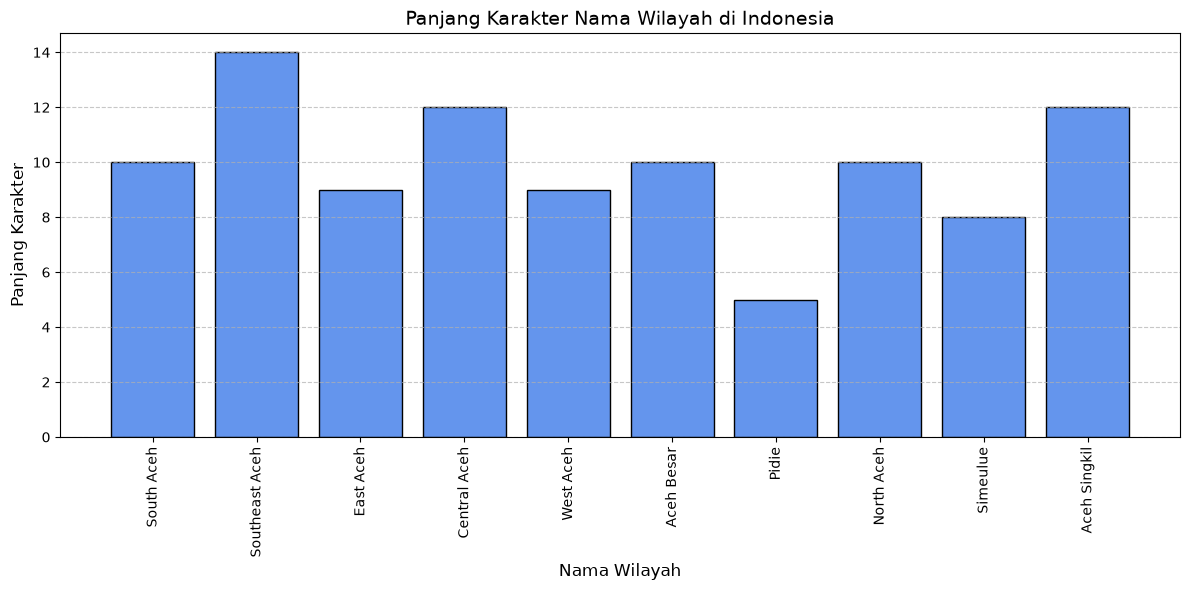

In [22]:
# Taufiqurrahman_202431093

# Menampilkan hasil scraping menggunakan matplotlib dan plt.show()
import matplotlib.pyplot as plt

# Mengambil beberapa data contoh untuk divisualisasikan, misal 10 wilayah pertama
sample_data = df_scraped.head(10)

plt.figure(figsize=(12, 6))
plt.bar(
    sample_data['Nama_Wilayah'],
    sample_data['Panjang_Karakter'],
    color='cornflowerblue',
    edgecolor='black',
)

plt.title('Panjang Karakter Nama Wilayah di Indonesia', fontsize=14)
plt.xlabel('Nama Wilayah', fontsize=12)
plt.ylabel('Panjang Karakter', fontsize=12)
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## Regresi Linear

In [23]:
# Taufiqurrahman_202431093

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Agar grafik langsung tampil di Jupyter Notebook
%matplotlib inline

In [24]:
# Taufiqurrahman_202431093

# Baca dataset hasil scraping dari Praktikum 2
df = pd.read_csv('indonesia_regions_scraping.csv')

# Buang data kosong pada kolom x dan y
df = df.dropna(subset=['Panjang_Karakter', 'Statistik_1'])

# Tampilkan beberapa baris data teratas
df.head()

,Nama_Wilayah,Provinsi,Statistik_1,Panjang_Karakter
0,South Aceh,Tapaktuan,100.0,10
1,Southeast Aceh,Kutacane,140.0,14
2,East Aceh,Idi Rayeuk,90.0,9
3,Central Aceh,Takengon,120.0,12
4,West Aceh,Meulaboh,90.0,9


In [25]:
# Taufiqurrahman_202431093

# Tentukan nilai x (fitur) dan y (target)
X = df[['Panjang_Karakter']].values
y = df['Statistik_1'].values

In [26]:
# Taufiqurrahman_202431093

# Bagi data latih dan data uji (test_size = 0.2, random_state = 0)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)

In [27]:
# Taufiqurrahman_202431093

# Buat model LinearRegression
model = LinearRegression()

# Latih model (fit) dengan data latih
model.fit(X_train, y_train)

# Prediksi data uji
y_pred = model.predict(X_test)

In [28]:
# Taufiqurrahman_202431093

# Evaluasi model: tampilkan Koefisien, Intercept, MSE, dan R2 Score
coef = model.coef_[0]
intercept = model.intercept_
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Koefisien (b): {coef}')
print(f'Intercept (a): {intercept}')
print(f'Mean Squared Error (MSE): {mse}')
print(f'R2 Score: {r2}')

Koefisien (b): 10.0
Intercept (a): 1.4210854715202004e-14
Mean Squared Error (MSE): 1.637419392458749e-28
R2 Score: 1.0


In [29]:
# Taufiqurrahman_202431093

# Menulis persamaan regresinya (Y = a + bx)
print('Persamaan Regresi Linear:')
print(f'Y = {intercept:.4f} + {coef:.4f}X')

Persamaan Regresi Linear:
Y = 0.0000 + 10.0000X


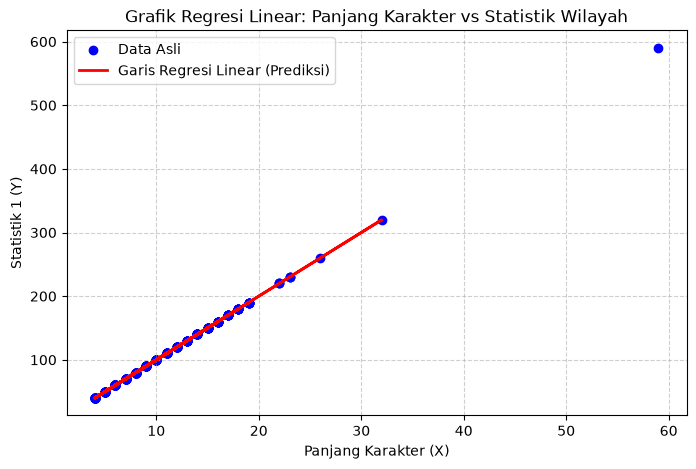

In [30]:
# Taufiqurrahman_202431093

# Visualisasi data asli dan garis regresi
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', label='Data Asli')
plt.plot(
    X_test,
    y_pred,
    color='red',
    linewidth=2,
    label='Garis Regresi Linear (Prediksi)',
)

plt.title('Grafik Regresi Linear: Panjang Karakter vs Statistik Wilayah')
plt.xlabel('Panjang Karakter (X)')
plt.ylabel('Statistik 1 (Y)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## Decision Tree

In [31]:
# Taufiqurrahman_202431093

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import tree
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier

# Agar grafik langsung tampil di Jupyter Notebook
%matplotlib inline

In [32]:
# Taufiqurrahman_202431093

# Baca dataset hasil scraping dari Praktikum 2
df = pd.read_csv('indonesia_regions_scraping.csv')

# Tampilkan 5 baris pertama data
df.head()

,Nama_Wilayah,Provinsi,Statistik_1,Panjang_Karakter
0,South Aceh,Tapaktuan,100.0,10
1,Southeast Aceh,Kutacane,140.0,14
2,East Aceh,Idi Rayeuk,90.0,9
3,Central Aceh,Takengon,120.0,12
4,West Aceh,Meulaboh,90.0,9


In [33]:
# Taufiqurrahman_202431093

# Lihat informasi data (info())
print('--- Informasi Data ---')
df.info()

# Lihat deskripsi statistik (describe())
print('\n--- Deskripsi Statistik ---')
df.describe()

--- Informasi Data ---
<class 'pandas.DataFrame'>
RangeIndex: 551 entries, 0 to 550
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Nama_Wilayah      551 non-null    str    
 1   Provinsi          551 non-null    str    
 2   Statistik_1       551 non-null    float64
 3   Panjang_Karakter  551 non-null    int64  
dtypes: float64(1), int64(1), str(2)
memory usage: 17.3 KB

--- Deskripsi Statistik ---


,Statistik_1,Panjang_Karakter
count,551.000000,551.000000
mean,94.736842,9.473684
std,47.019084,4.701908
min,40.000000,4.000000
25%,60.000000,6.000000
50%,90.000000,9.000000
75%,120.000000,12.000000
max,590.000000,59.000000


In [34]:
# Taufiqurrahman_202431093

# Cek data kosong (isna().sum())
print('Jumlah Data Kosong:')
print(df.isna().sum())

Jumlah Data Kosong:
Nama_Wilayah        0
Provinsi            0
Statistik_1         0
Panjang_Karakter    0
dtype: int64


In [35]:
# Taufiqurrahman_202431093

# Lihat isi unik kolom target (unique())
print("Nilai unik kolom 'Provinsi' (Target):")
print(df['Provinsi'].unique())

# Komentar Arti Kelas / Target:
# - Setiap kelas pada kolom 'Provinsi' merepresentasikan wilayah administratif
#   provinsi tempat kabupaten/kota tersebut berada di Indonesia, yang akan diprediksi
#   berdasarkan fitur karakteristik angkanya.

Nilai unik kolom 'Provinsi' (Target):
<StringArray>
[  'Tapaktuan',    'Kutacane',  'Idi Rayeuk',    'Takengon',    'Meulaboh',
      'Jantho',       'Sigli',   'Lhoksukon',    'Sinabang',     'Singkil',
 ...
     'Merauke',    'Kumurkek',      'Waisai',       'Aimas',  'Teminabuan',
         'Fef', 'South Papua',     'Jakarta',   'West Java',       'Papua']
Length: 491, dtype: str


In [36]:
# Taufiqurrahman_202431093

# Pisahkan fitur x dan target y (drop)
X_raw = df[['Panjang_Karakter', 'Statistik_1']]
y_raw = df['Provinsi']

In [37]:
# Taufiqurrahman_202431093

# Ubah target teks menjadi angka dengan LabelEncoder
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y_raw)

# Ubah x dan y menjadi array angka (dtype float64 untuk x dan int64 untuk y)
X = np.array(X_raw, dtype=np.float64)
y = np.array(y_encoded, dtype=np.int64)

In [38]:
# Taufiqurrahman_202431093

# Bagi data latih dan uji: test_size = 0.3, random_state = 0
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

In [39]:
# Taufiqurrahman_202431093

# Buat model DecisionTreeClassifier() dan latih (fit)
clf = DecisionTreeClassifier(random_state=0)
clf.fit(X_train, y_train)

C:\Users\fieqi\.conda\envs\notebook-env\Lib\site-packages\sklearn\tree\_classes.py:289: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)


,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

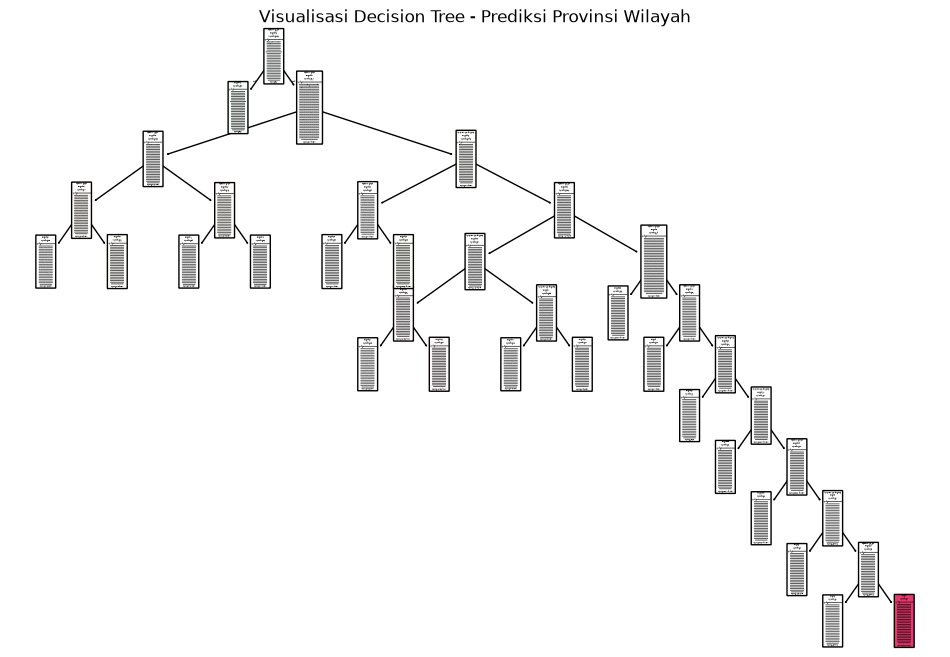

In [40]:
# Taufiqurrahman_202431093

# Tampilkan visualisasi pohon (tree.plot_tree)
plt.figure(figsize=(12, 8))
tree.plot_tree(
    clf,
    feature_names=['Panjang_Karakter', 'Statistik_1'],
    class_names=[str(c) for c in encoder.classes_],
    filled=True,
    rounded=True,
)
plt.title('Visualisasi Decision Tree - Prediksi Provinsi Wilayah')
plt.show()

In [41]:
# Taufiqurrahman_202431093

# Uji dengan 1 data baru (predict)
# Contoh data baru: [Panjang Karakter, Statistik_1]
new_data = np.array([[12.0, 150.0]])
prediction = clf.predict(new_data)
predicted_class = encoder.inverse_transform(prediction)

print(f'Hasil Prediksi untuk 1 Data Baru: {predicted_class[0]}')

Hasil Prediksi untuk 1 Data Baru: 0.848 (Very High)


In [43]:
# Taufiqurrahman_202431093

# Prediksi pada data uji untuk evaluasi
y_pred = clf.predict(X_test)

# Hitung akurasi (accuracy_score)
acc = accuracy_score(y_test, y_pred)
print(f'Akurasi Model: {acc:.4f}')

# Tampilkan classification_report dengan menyesuaikan labels yang ada pada y_test dan y_pred
unique_labels = np.unique(np.concatenate((y_test, y_pred)))
print('\nClassification Report:')
print(
    classification_report(
        y_test,
        y_pred,
        labels=unique_labels,
        target_names=[encoder.classes_[i] for i in unique_labels],
        zero_division=0,
    )
)

Akurasi Model: 0.0241

Classification Report:
                    precision    recall  f1-score   support

      0.738 (High)       0.00      0.00      0.00         1
      0.757 (High)       0.00      0.00      0.00         1
      0.765 (High)       0.00      0.00      0.00         0
      0.767 (High)       0.00      0.00      0.00         1
      0.770 (High)       0.00      0.00      0.00         1
      0.775 (High)       0.00      0.00      0.00         1
      0.777 (High)       0.00      0.00      0.00         1
      0.779 (High)       0.00      0.00      0.00         1
      0.781 (High)       0.00      0.00      0.00         0
      0.782 (High)       0.00      0.00      0.00         0
      0.785 (High)       0.00      0.00      0.00         1
      0.788 (High)       0.00      0.00      0.00         1
      0.790 (High)       0.00      0.00      0.00         1
      0.791 (High)       0.00      0.00      0.00         0
      0.792 (High)       0.00      0.00      0.00    

## Naive Bayes

In [44]:
# Taufiqurrahman_202431093

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import LabelEncoder

# Agar grafik tampil langsung di Jupyter Notebook
%matplotlib inline

In [45]:
# Taufiqurrahman_202431093

# Baca dataset dari file CSV (pastikan file heart.csv berada di satu folder)
df = pd.read_csv('heart.csv')

# Tampilkan data teratas
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [46]:
# Taufiqurrahman_202431093

# Lihat informasi data (info())
print('--- Informasi Data ---')
df.info()

# Lihat deskripsi statistik (describe())
print('\n--- Deskripsi Statistik ---')
df.describe()

--- Informasi Data ---
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB

--- Deskripsi Statistik ---


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [47]:
# Taufiqurrahman_202431093

# Pisahkan fitur numerik
numeric_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(f'Jumlah Fitur Numerik: {len(numeric_features)}')
print('Daftar Fitur Numerik:', numeric_features)

Jumlah Fitur Numerik: 7
Daftar Fitur Numerik: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'HeartDisease']


In [48]:
# Taufiqurrahman_202431093

# Pisahkan fitur kategorikal
categorical_features = df.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print(f'Jumlah Fitur Kategorikal: {len(categorical_features)}')
print('Daftar Fitur Kategorikal:', categorical_features)

Jumlah Fitur Kategorikal: 5
Daftar Fitur Kategorikal: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']


C:\Users\fieqi\AppData\Local\Temp\ipykernel_9596\3317340890.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(


In [49]:
# Taufiqurrahman_202431093

# Tampilkan isi unik tiap fitur kategorikal
for col in categorical_features:
  print(f"Nilai unik pada '{col}': {df[col].unique()}")

Nilai unik pada 'Sex': <StringArray>
['M', 'F']
Length: 2, dtype: str
Nilai unik pada 'ChestPainType': <StringArray>
['ATA', 'NAP', 'ASY', 'TA']
Length: 4, dtype: str
Nilai unik pada 'RestingECG': <StringArray>
['Normal', 'ST', 'LVH']
Length: 3, dtype: str
Nilai unik pada 'ExerciseAngina': <StringArray>
['N', 'Y']
Length: 2, dtype: str
Nilai unik pada 'ST_Slope': <StringArray>
['Up', 'Flat', 'Down']
Length: 3, dtype: str


In [50]:
# Taufiqurrahman_202431093

# Ubah fitur kategorikal menjadi angka
df_encoded = df.copy()
encoder = LabelEncoder()

for col in categorical_features:
  df_encoded[col] = encoder.fit_transform(df_encoded[col].astype(str))

# Tampilkan hasil perubahan (head())
df_encoded.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,1,140,289,0,1,172,0,0.0,2,0
1,49,0,2,160,180,0,1,156,0,1.0,1,1
2,37,1,1,130,283,0,2,98,0,0.0,2,0
3,48,0,0,138,214,0,1,108,1,1.5,1,1
4,54,1,2,150,195,0,1,122,0,0.0,2,0


In [51]:
# Taufiqurrahman_202431093

# Tentukan target y (kolom terakhir yaitu 'HeartDisease')
target_column = df_encoded.columns[-1]

X = df_encoded.drop(columns=[target_column])
y = df_encoded[target_column]

In [52]:
# Taufiqurrahman_202431093

# Bagi data latih dan uji: test_size = 0.25, random_state = 0
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0
)

In [53]:
# Taufiqurrahman_202431093

# Buat model GaussianNB() dan latih (fit)
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[318.,370.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.46,0.54]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.122e-05
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](11,)","['Age','Sex','ChestPainType',...,'ExerciseAngina','Oldpeak','ST_Slope']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 11)","[[50.93, 0.66, 1.17,..., 0.14, 0.39, 1.76], [55.79, 0.89, 0.46,..., 0.64, 1.3 , 1.03]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 11)","[[89.06, 0.22, 0.76,..., 0.12, 0.47, 0.24], [76.89, 0.1 , 0.79,..., 0.23, 1.27, 0.24]]"


In [54]:
# Taufiqurrahman_202431093

# Prediksi data latih dan data uji
y_train_pred = nb_model.predict(X_train)
y_test_pred = nb_model.predict(X_test)

print('Prediksi data latih dan data uji berhasil dilakukan.')

Prediksi data latih dan data uji berhasil dilakukan.


=== EVALUASI DATA LATIH (TRAINING) ===
Confusion Matrix:
[[274  44]
 [ 51 319]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.86      0.85       318
           1       0.88      0.86      0.87       370

    accuracy                           0.86       688
   macro avg       0.86      0.86      0.86       688
weighted avg       0.86      0.86      0.86       688



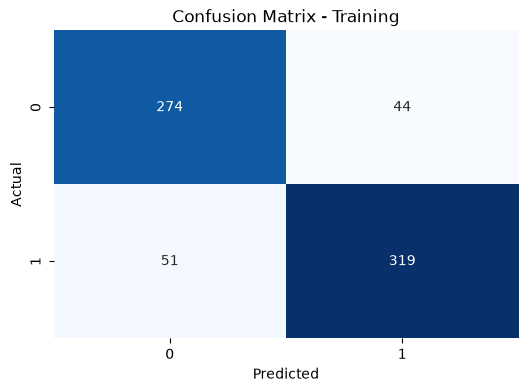

In [55]:
# Taufiqurrahman_202431093

print('=== EVALUASI DATA LATIH (TRAINING) ===')
print('Confusion Matrix:')
cm_train = confusion_matrix(y_train, y_train_pred)
print(cm_train)

print('\nClassification Report:')
print(classification_report(y_train, y_train_pred, zero_division=0))

# Heatmap seaborn berjudul “Confusion Matrix - Training”
plt.figure(figsize=(6, 4))
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix - Training')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

=== EVALUASI DATA UJI (TESTING) ===
Confusion Matrix:
[[ 73  19]
 [ 16 122]]

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.79      0.81        92
           1       0.87      0.88      0.87       138

    accuracy                           0.85       230
   macro avg       0.84      0.84      0.84       230
weighted avg       0.85      0.85      0.85       230



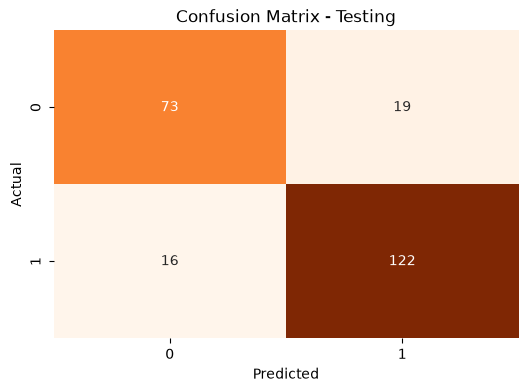

In [56]:
# Taufiqurrahman_202431093

print('=== EVALUASI DATA UJI (TESTING) ===')
print('Confusion Matrix:')
cm_test = confusion_matrix(y_test, y_test_pred)
print(cm_test)

print('\nClassification Report:')
print(classification_report(y_test, y_test_pred, zero_division=0))

# Heatmap seaborn berjudul “Confusion Matrix - Testing”
plt.figure(figsize=(6, 4))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Oranges', cbar=False)
plt.title('Confusion Matrix - Testing')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [57]:
# Taufiqurrahman_202431093

# Uji dengan 1 data baru (predict)
new_sample = X_test.iloc[[0]]
prediction = nb_model.predict(new_sample)
prediction_proba = nb_model.predict_proba(new_sample)

print('Data Baru yang Diuji:')
print(new_sample)
print(f'\nHasil Prediksi Kelas: {prediction[0]}')
print(f'Probabilitas Prediksi: {prediction_proba[0]}')

Data Baru yang Diuji:
     Age  Sex  ChestPainType  RestingBP  Cholesterol  FastingBS  RestingECG  \
306   55    1              0        115            0          1           1   

     MaxHR  ExerciseAngina  Oldpeak  ST_Slope  
306    155               0      0.1         1  

Hasil Prediksi Kelas: 1
Probabilitas Prediksi: [0.00232158 0.99767842]
